# Health Data Explorer – Analyse-Notebook

Dieses Notebook beantwortet die sieben geführten Fragen und drei eigene Fragen zum Health-Datensatz (50.000 Personen: Größe, Gewicht, Alter, Geschlecht, Aktivitätslevel, Rauchstatus).

**Wichtige Vorab-Erkenntnis:** Die Spalte `BF%` ist in diesem Datensatz nicht gemessen, sondern mit der Deurenberg-Formel aus BMI, Alter und Geschlecht berechnet. Das beeinflusst die Interpretation mehrerer Ergebnisse und wird in der EDA nachgewiesen.

## Setup

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 100
plt.rcParams.update({'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.labelsize': 12,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'grid.color': '#E3E3E3'})


def add_bar_labels(ax, fmt='%.1f', **kwargs):
    # Beschriftet alle Balken; der weiße Hintergrund verhindert, dass Gitterlinien den Text durchkreuzen
    for c in ax.containers:
        ax.bar_label(c, fmt=fmt, padding=3,
                     bbox=dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.95),
                     **kwargs)

import os, glob

def find_data_file(pattern='health_data_processed*.csv'):
    # Sucht die CSV im aktuellen Ordner, in Colab unter /content und in Google Drive
    for folder in ['.', '/content', '/content/drive/MyDrive']:
        hits = sorted(glob.glob(os.path.join(folder, pattern)))
        if hits:
            return hits[0]
    return None

path = find_data_file()
if path is None:
    try:
        # Google Colab: Datei per Dialog hochladen ("Dateien auswählen" klicken)
        from google.colab import files
        uploaded = files.upload()
        path = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError("health_data_processed.csv nicht gefunden. Lege sie in den Ordner dieses Notebooks.")

print("Datei:", path)
df = pd.read_csv(path)

print(f"Rows: {len(df):,}")
print(f"Columns: {list(df.columns)}")
df.head()

Datei: ./health_data_processed.csv
Rows: 50,002
Columns: ['Height', 'Weight', 'Gender', 'Age', 'Activity_Level', 'Smoker', 'BMI', 'bmi_category', 'BF%', 'message', 'bf_healthy']


,Height,Weight,Gender,Age,Activity_Level,Smoker,BMI,bmi_category,BF%,message,bf_healthy
0,1.62,53.80,F,19,Sedentary,No,20.50,Normal weight,23.57,Great work – your BMI is in the healthy range!...,True
1,1.72,76.12,M,56,Lightly Active,No,25.73,Overweight,27.56,Your BMI is in the overweight range. Aim for g...,False
2,1.80,87.38,M,69,Sedentary,No,26.97,Overweight,32.03,Your BMI is in the overweight range. Aim for g...,False
3,1.80,74.28,M,20,Very Active,No,22.93,Normal weight,15.92,Great work – your BMI is in the healthy range!...,True
4,1.63,62.76,F,54,Lightly Active,No,23.62,Normal weight,35.36,Great work – your BMI is in the healthy range!...,False


### Die Hilfsfunktionen

Vier vorgegebene Funktionen: `calculate_bmi`, `categorize_bmi`, `calculate_body_fat` und `healthy_bf` (zusammen mit dem Dictionary `healthy_bf_ranges`).

In [19]:
def calculate_bmi(weight_kg, height_m):
    """BMI = weight in kg divided by height in metres squared."""
    return weight_kg / (height_m ** 2)


def categorize_bmi(bmi):
    """Returns the standard WHO BMI category for a given BMI value."""
    if bmi < 18.5:
        return 'Underweight'
    elif bmi < 25:
        return 'Normal weight'
    elif bmi < 30:
        return 'Overweight'
    else:
        return 'Obese'


def calculate_body_fat(bmi, age, gender):
    """Body fat % using the Deurenberg formula. Gender is 'M' or 'F'."""
    gender_factor = 1 if gender == 'M' else 0
    return 1.20 * bmi + 0.23 * age - 10.8 * gender_factor - 5.4


# Healthy BF% ranges by age bracket and gender
# Each entry is (lower_bound, upper_bound), both inclusive
healthy_bf_ranges = {
    '18-29': {'M': (9, 20),    'F': (19, 28)},
    '30-39': {'M': (11, 21),   'F': (21.5, 29)},
    '40-49': {'M': (13, 22),   'F': (24, 31)},
    '50-59': {'M': (16, 24),   'F': (25, 33)},
    '60+':   {'M': (19, 25),   'F': (28, 35)},
}


def healthy_bf(row):
    """Returns True if the person's BF% falls in the healthy range for
    their age bracket and gender. Expects a row with Age, Gender, BF%."""
    age = row['Age']
    if age <= 29:
        bracket = '18-29'
    elif age <= 39:
        bracket = '30-39'
    elif age <= 49:
        bracket = '40-49'
    elif age <= 59:
        bracket = '50-59'
    else:
        bracket = '60+'

    lo, hi = healthy_bf_ranges[bracket][row['Gender']]
    return lo <= row['BF%'] <= hi

## Exploratory Data Analysis (EDA)

Bevor ich die Fragen beantworte, prüfe ich Struktur und Qualität des Datensatzes: Form, Datentypen, fehlende Werte, Kennzahlen und die Ausprägungen der kategorialen Spalten.

In [20]:
# Form des Datensatzes
print("Shape:", df.shape)

# Spalten, Datentypen, fehlende Werte
df.info()

# Statistische Kennzahlen der numerischen Spalten
display(df.describe().round(2))

# Ausprägungen der kategorialen Spalten
print("\nUnique values:")
print("Gender:", df['Gender'].unique())
print("Activity_Level:", df['Activity_Level'].unique())
print("Smoker:", df['Smoker'].unique())
print("BMI Category:", df['bmi_category'].unique())
print("bf_healthy:", df['bf_healthy'].unique())

Shape: (50002, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50002 entries, 0 to 50001
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Height          50002 non-null  float64
 1   Weight          50002 non-null  float64
 2   Gender          50002 non-null  object 
 3   Age             50002 non-null  int64  
 4   Activity_Level  50002 non-null  object 
 5   Smoker          50002 non-null  object 
 6   BMI             50002 non-null  float64
 7   bmi_category    50002 non-null  object 
 8   BF%             50002 non-null  float64
 9   message         50002 non-null  object 
 10  bf_healthy      50002 non-null  bool   
dtypes: bool(1), float64(4), int64(1), object(5)
memory usage: 3.9+ MB


,Height,Weight,Age,BMI,BF%
count,50002.00,50002.00,50002.00,50002.00,50002.00
mean,1.69,67.35,49.07,23.50,28.43
std,0.10,11.21,18.21,2.28,7.43
min,1.45,45.00,18.00,15.84,8.69
25%,1.62,59.08,33.00,21.93,22.93
50%,1.68,66.57,49.00,23.44,28.41
75%,1.76,75.02,65.00,25.00,33.65
max,2.00,111.33,80.00,34.46,51.03



Unique values:
Gender: ['F' 'M']
Activity_Level: ['Sedentary' 'Lightly Active' 'Very Active' 'Moderately Active' 'Moderate']
Smoker: ['No' 'Yes']
BMI Category: ['Normal weight' 'Overweight' 'Underweight' 'Obese']
bf_healthy: [ True False]


### Datenqualität

Die Unique-Werte zeigen bei `Activity_Level` fünf statt vier Stufen: Neben Sedentary, Lightly Active, Moderately Active und Very Active taucht `Moderate` auf. Ich prüfe, wie oft das vorkommt, ob es Duplikate gibt, wie `BF%` entstanden ist und was die Spalte `message` enthält.

In [21]:
# 1) Aktivitätslevel: wie oft kommt jede Stufe vor?
print(df['Activity_Level'].value_counts())

# 2) Komplett identische Zeilen
print("\nIdentische Zeilen:", df.duplicated().sum())

# 3) Ist BF% gemessen oder berechnet? Vergleich mit der Deurenberg-Formel
bf_check = 1.20 * df['BMI'] + 0.23 * df['Age'] - 10.8 * (df['Gender'] == 'M') - 5.4
print("Max. Abweichung BF% vs. Formel:", round((bf_check - df['BF%']).abs().max(), 3))

# 4) Wie viele verschiedene Nachrichten gibt es?
print("Verschiedene message-Texte:", df['message'].nunique())

Activity_Level
Lightly Active       17596
Sedentary            16956
Moderately Active    11621
Very Active           3828
Moderate                 1
Name: count, dtype: int64

Identische Zeilen: 96
Max. Abweichung BF% vs. Formel: 0.016
Verschiedene message-Texte: 4


In [22]:
# Bereinigung: die eine Zeile mit dem ungültigen Aktivitätslevel 'Moderate' entfernen
df = df[df['Activity_Level'] != 'Moderate'].copy()

# Duplikate nur markieren, nicht löschen (bei kontinuierlichen Messwerten nicht automatisch Fehler)
df['is_duplicate'] = df.duplicated(keep=False)

# Gesund-Flag zeilenweise mit der vorgegebenen Funktion neu berechnen und gegen die Spalte prüfen
df['healthy_flag'] = df.apply(healthy_bf, axis=1)
print("Abweichungen healthy_flag vs. bf_healthy:", (df['healthy_flag'] != df['bf_healthy']).sum())
print("Zeilen nach Bereinigung:", len(df))

Abweichungen healthy_flag vs. bf_healthy: 11
Zeilen nach Bereinigung: 50001


### EDA – Interpretation

Der Datensatz hat 50.002 Zeilen und 11 Spalten ohne fehlende Werte. Die Datentypen sind korrekt. Vier Auffälligkeiten:

1. **Ungültige Kategorie:** Das Aktivitätslevel `Moderate` kommt genau **einmal** vor (die anderen Stufen haben tausende Zeilen). Ich habe die Zeile entfernt, sonst würde sie in Frage 2 einen scheinbar höchsten Balken erzeugen.
2. **Duplikate:** 96 Zeilen (0,2 %) sind komplett identisch. Ich markiere sie in `is_duplicate`, lösche sie aber nicht.
3. **`BF%` ist berechnet:** Die Werte entsprechen der Deurenberg-Formel aus BMI, Alter und Geschlecht, die Abweichung liegt nur bei Rundungsfehlern. Aktivität und Rauchen kommen in der Formel nicht vor und können den Körperfettanteil in diesem Datensatz daher nicht direkt beeinflussen. Sichtbare Unterschiede entstehen nur durch die unterschiedliche Alters- und Geschlechtsmischung der Gruppen.

4. **Gesund-Flag:** Die vorgegebene Funktion `healthy_bf()` und die Spalte `bf_healthy` stimmen bis auf 11 Randfälle (0,02 %) überein, fast alle Männer im Alter 18–21 mit einem BF% knapp unter 10. Für die Fragen nutze ich `bf_healthy` und in Frage 6 wie verlangt `healthy_bf()`.

Außerdem enthält `message` nur vier verschiedene Texte (siehe Teil 2, Frage 2).

## Part 1 — Guided Questions

### Question 1 — BMI Category Distribution by Gender

**Vorgehen:** Ich zähle pro Geschlecht die Personen je BMI-Kategorie, berechne die Anteile innerhalb jedes Geschlechts und stelle sie mit Seaborn dar. Die Kategorien sind logisch von Underweight bis Obese sortiert. Zusätzlich gibt es eine eingefärbte Pivot-Tabelle, die die Unterschiede schnell sichtbar macht.

Anzahl:


Gender,F,M
bmi_category,,
Underweight,321,137
Normal weight,19690,17332
Overweight,3779,8573
Obese,17,152


Anteil innerhalb des Geschlechts (%):


Gender,F,M
bmi_category,,
Underweight,1.3,0.5
Normal weight,82.7,66.2
Overweight,15.9,32.7
Obese,0.1,0.6


Eingefärbte Pivot-Tabelle (Anteil in %):


Gender,F,M
bmi_category,,
Underweight,1.3%,0.5%
Normal weight,82.7%,66.2%
Overweight,15.9%,32.7%
Obese,0.1%,0.6%


Datengrundlage des Diagramms:


,bmi_category,Gender,percent
0,Underweight,F,1.3
1,Normal weight,F,82.7
2,Overweight,F,15.9
3,Obese,F,0.1
4,Underweight,M,0.5
5,Normal weight,M,66.2
6,Overweight,M,32.7
7,Obese,M,0.6


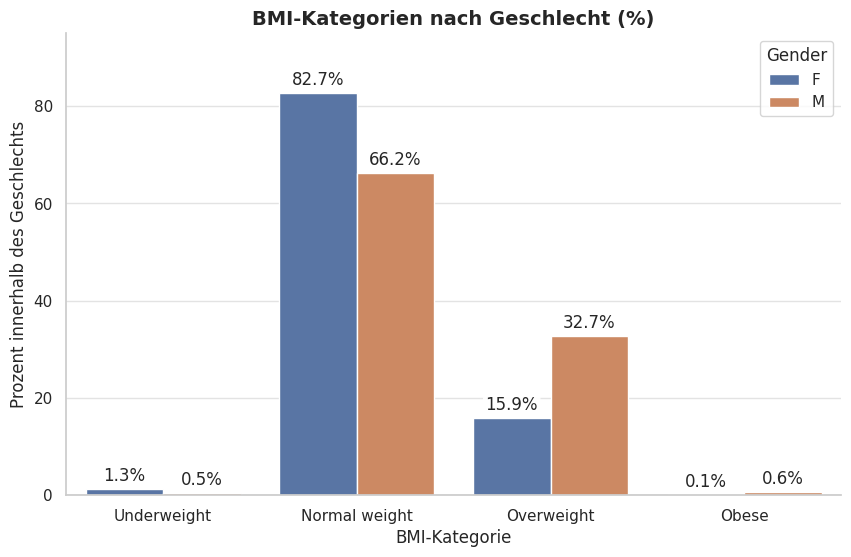

In [23]:
bmi_order = ['Underweight', 'Normal weight', 'Overweight', 'Obese']

counts = pd.crosstab(df['bmi_category'], df['Gender']).loc[bmi_order]
percent = (pd.crosstab(df['bmi_category'], df['Gender'], normalize='columns') * 100).loc[bmi_order].round(1)

print("Anzahl:")
display(counts)
print("Anteil innerhalb des Geschlechts (%):")
display(percent)

bmi_gender = (percent.reset_index()
                     .melt(id_vars='bmi_category', var_name='Gender', value_name='percent'))
print("Eingefärbte Pivot-Tabelle (Anteil in %):")
display(percent.style.format("{:.1f}%").background_gradient(cmap="Greens")
               .set_caption("BMI-Verteilung nach Geschlecht (%)"))

print("Datengrundlage des Diagramms:")
display(bmi_gender)

plt.figure(figsize=(10, 6))
ax = sns.barplot(data=bmi_gender, x='bmi_category', y='percent', hue='Gender', order=bmi_order)
add_bar_labels(ax, '%.1f%%')
ax.set_ylim(0, 95)
plt.title('BMI-Kategorien nach Geschlecht (%)')
plt.xlabel('BMI-Kategorie')
plt.ylabel('Prozent innerhalb des Geschlechts')
plt.show()

**Interpretation:** Frauen liegen mit 82,7 % deutlich häufiger im Normalgewicht als Männer (66,2 %). Männer sind mit 32,7 % doppelt so oft übergewichtig wie Frauen (15,9 %). Adipositas ist insgesamt selten (169 Personen), bei Männern mit 0,6 % aber sechsmal so häufig wie bei Frauen (0,1 %). Untergewicht kommt bei Frauen etwas häufiger vor (1,3 % vs. 0,5 %).

### Question 2 — Average Body Fat Percentage by Activity Level

**Vorgehen:** Ich gruppiere nach `Activity_Level` und berechne den mittleren `BF%`, zusätzlich das mittlere Alter und den Anteil mit gesundem Körperfett. Das Alter nehme ich dazu, weil es in der Formel für `BF%` steckt.

,mean_BF,mean_Age,healthy_pct,n
Activity_Level,,,,
Very Active,26.5,41.7,50.4,3828
Moderately Active,27.2,44.8,46.0,11621
Lightly Active,28.5,49.6,37.8,17596
Sedentary,29.6,53.1,32.9,16956


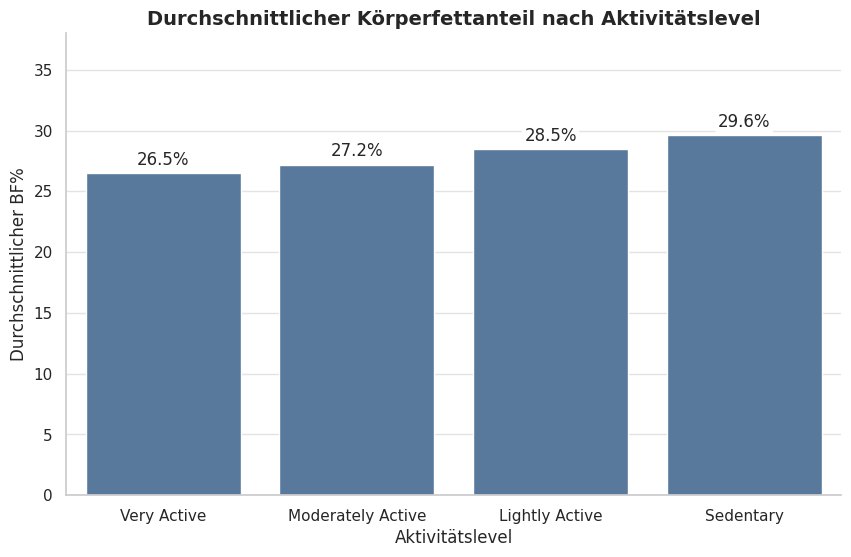

In [24]:
act = (df.groupby('Activity_Level')
         .agg(mean_BF=('BF%', 'mean'), mean_Age=('Age', 'mean'),
              healthy_pct=('bf_healthy', lambda s: s.mean() * 100), n=('BF%', 'count'))
         .round(1)
         .sort_values('mean_BF'))
display(act)

plt.figure(figsize=(10, 6))
ax = sns.barplot(data=act.reset_index(), x='Activity_Level', y='mean_BF', color='#4C78A8')
add_bar_labels(ax, '%.1f%%')
ax.set_ylim(0, 38)
plt.title('Durchschnittlicher Körperfettanteil nach Aktivitätslevel')
plt.xlabel('Aktivitätslevel')
plt.ylabel('Durchschnittlicher BF%')
plt.show()

**Interpretation:** Sehr aktive Personen haben mit 26,5 % den niedrigsten mittleren Körperfettanteil, Sitzende mit 29,6 % den höchsten. Das ist erwartbar und überrascht zunächst nicht. Der Unterschied ist aber überwiegend ein **Alterseffekt**: Sehr Aktive sind im Mittel 41,7 Jahre alt, Sitzende 53,1. Elf Jahre Altersunterschied ergeben mit dem Faktor 0,23 aus der Formel rund 2,6 der gut 3 Prozentpunkte Differenz. Ob die Aktivität selbst eine Rolle spielt, prüfe ich in Teil 2, Frage 1.

### Question 3 — Smokers vs Non-Smokers: who has healthier body fat?

**Vorgehen:** Ich berechne den Anteil gesunder Körperfettwerte für Raucher und Nichtraucher. Weil Geschlecht den Anteil stark beeinflusst, prüfe ich zusätzlich die Geschlechtsverteilung und die Anteile getrennt nach Geschlecht. Ein Chi-Quadrat-Test zeigt, ob der Unterschied über Zufall hinausgeht.

,Smoker,healthy_count,total_count,healthy_share,healthy_percent
0,No,16933,43640,0.388016,38.8
1,Yes,2560,6361,0.402452,40.2


Chi-Quadrat-Test Rauchen vs. gesund: p = 0.028

Anteil Männer je Rauchstatus:


Gender,F,M
Smoker,,
No,48.9,51.1
Yes,38.9,61.1


Anteil gesund (%) nach Geschlecht und Rauchstatus:


Smoker,No,Yes
Gender,,
F,35.1,35.7
M,42.3,43.2


Datengrundlage des Diagramms:


,Gender,Smoker,bf_healthy
0,F,No,35.1
1,F,Yes,35.7
2,M,No,42.3
3,M,Yes,43.2


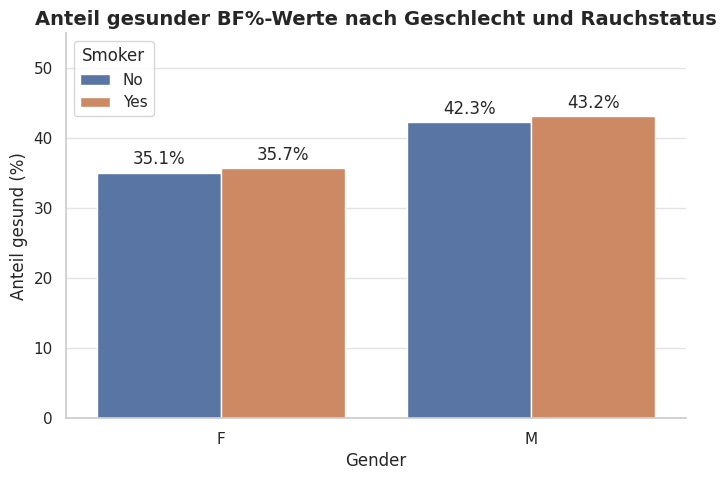

In [25]:
smoke = (df.groupby('Smoker')['bf_healthy']
           .agg(healthy_count='sum', total_count='count', healthy_share='mean')
           .reset_index())
smoke['healthy_percent'] = (smoke['healthy_share'] * 100).round(1)
display(smoke)

chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(df['Smoker'], df['bf_healthy']))
print(f"Chi-Quadrat-Test Rauchen vs. gesund: p = {p:.3f}")

print("\nAnteil Männer je Rauchstatus:")
display((pd.crosstab(df['Smoker'], df['Gender'], normalize='index') * 100).round(1))

print("Anteil gesund (%) nach Geschlecht und Rauchstatus:")
by_gs = (df.groupby(['Gender', 'Smoker'])['bf_healthy'].mean().mul(100).round(1).reset_index())
display(by_gs.pivot(index='Gender', columns='Smoker', values='bf_healthy'))

print("Datengrundlage des Diagramms:")
display(by_gs)

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=by_gs, x='Gender', y='bf_healthy', hue='Smoker')
add_bar_labels(ax, '%.1f%%')
ax.set_ylim(0, 55)
plt.title('Anteil gesunder BF%-Werte nach Geschlecht und Rauchstatus')
plt.ylabel('Anteil gesund (%)')
plt.show()

**Interpretation:** Raucher haben mit 40,2 % einen leicht *höheren* Anteil gesunder Körperfettwerte als Nichtraucher (38,8 %); der Unterschied ist statistisch knapp signifikant (p ≈ 0,03). Das ist **kein Gesundheitseffekt des Rauchens**: 61 % der Raucher sind Männer, bei den Nichtrauchern nur 51 %, und Männer erreichen häufiger den gesunden Bereich. Innerhalb eines Geschlechts liegt der Unterschied unter einem Prozentpunkt (Frauen 35,1 % vs. 35,7 %, Männer 42,3 % vs. 43,2 %). Die Daten zeigen keinen Zusammenhang zwischen Rauchen und Körperfettgesundheit. Es handelt sich um Beobachtungsdaten, und `BF%` ist berechnet, daher ist auch kein kausaler Effekt zu erwarten.

### Question 4 — BMI distribution among people over 45

**Vorgehen:** Ich filtere auf Personen über 45, wende `categorize_bmi()` erneut an (und prüfe, dass sie mit der vorhandenen Spalte übereinstimmt), zeige die BMI-Verteilung beider Gruppen nebeneinander und vergleiche Mittelwert, Streuung und Kategorien.

Kategorien stimmen mit Spalte überein: True
Personen über 45: 27,844
Datengrundlage der Histogramme (Kennzahlen des BMI):


,Full Dataset,Age > 45
count,50001.00,27844.00
mean,23.50,24.16
std,2.28,2.28
min,15.84,16.14
25%,21.93,22.59
50%,23.44,24.11
75%,25.00,25.68
max,34.46,34.46


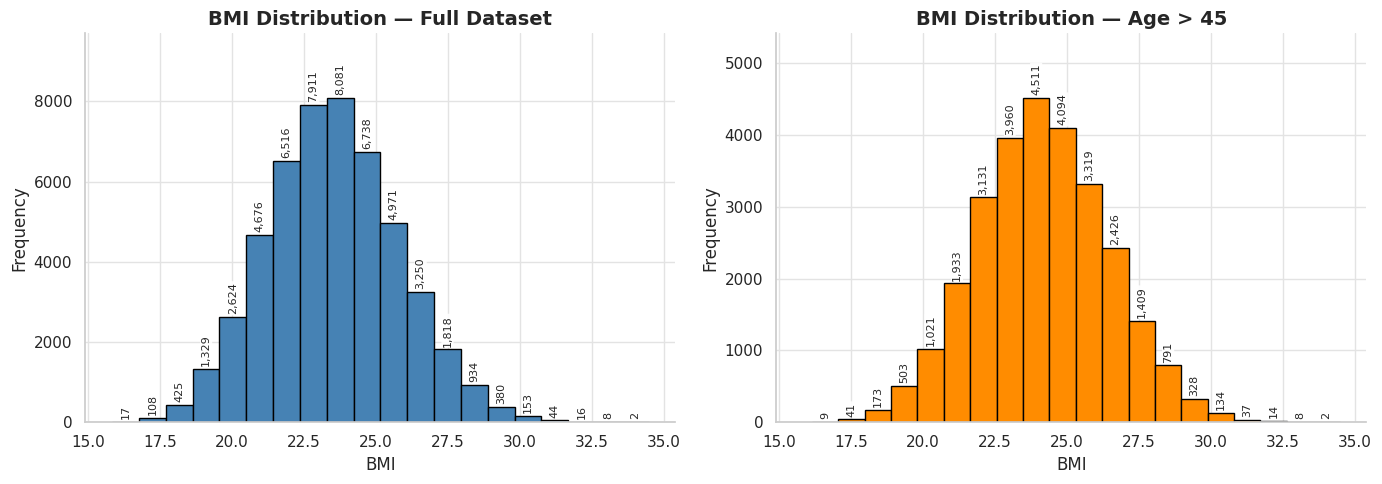

Mittelwert / Standardabweichung:
  Gesamt:   23.50 / 2.28
  Alter>45: 24.16 / 2.28
  Alter<=45: 22.68


,Full Dataset (%),Age > 45 (%),Full Dataset (count),Age > 45 (count)
bmi_category,,,,
Underweight,0.9,0.4,458,120
Normal weight,74.0,64.5,37022,17971
Overweight,24.7,34.4,12352,9587
Obese,0.3,0.6,169,166


In [26]:
df_over45 = df[df['Age'] > 45].copy()
df_over45['bmi_check'] = df_over45['BMI'].apply(categorize_bmi)
print("Kategorien stimmen mit Spalte überein:", (df_over45['bmi_check'] == df_over45['bmi_category']).all())
print(f"Personen über 45: {len(df_over45):,}")

print("Datengrundlage der Histogramme (Kennzahlen des BMI):")
display(pd.DataFrame({'Full Dataset': df['BMI'].describe(),
                      'Age > 45': df_over45['BMI'].describe()}).round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
n0, _, p0 = axes[0].hist(df['BMI'], bins=20, color='steelblue', edgecolor='black')
axes[0].set_title('BMI Distribution — Full Dataset')
axes[0].bar_label(p0, labels=[f'{int(v):,}' if v > 0 else '' for v in n0], fontsize=8, rotation=90, padding=2, bbox=dict(boxstyle='round,pad=0.1', facecolor='white', edgecolor='none', alpha=0.9))
n1, _, p1 = axes[1].hist(df_over45['BMI'], bins=20, color='darkorange', edgecolor='black')
axes[1].set_title('BMI Distribution — Age > 45')
axes[1].bar_label(p1, labels=[f'{int(v):,}' if v > 0 else '' for v in n1], fontsize=8, rotation=90, padding=2, bbox=dict(boxstyle='round,pad=0.1', facecolor='white', edgecolor='none', alpha=0.9))
for ax in axes:
    ax.set_xlabel('BMI')
    ax.set_ylabel('Frequency')
    ax.margins(y=0.2)
plt.tight_layout()
plt.show()

print("Mittelwert / Standardabweichung:")
print(f"  Gesamt:   {df['BMI'].mean():.2f} / {df['BMI'].std():.2f}")
print(f"  Alter>45: {df_over45['BMI'].mean():.2f} / {df_over45['BMI'].std():.2f}")
print(f"  Alter<=45: {df[df['Age'] <= 45]['BMI'].mean():.2f}")

bmi_comparison = pd.DataFrame({
    'Full Dataset (%)': (df['bmi_category'].value_counts(normalize=True) * 100).round(1),
    'Age > 45 (%)': (df_over45['bmi_category'].value_counts(normalize=True) * 100).round(1),
    'Full Dataset (count)': df['bmi_category'].value_counts(),
    'Age > 45 (count)': df_over45['bmi_category'].value_counts(),
}).loc[bmi_order]
display(bmi_comparison)

**Interpretation:** Die Verteilung der über 45-Jährigen ist nach rechts verschoben: Der mittlere BMI liegt bei 24,2 (Gesamtdatensatz 23,5, bis 45 Jahre 22,7). Die **Streuung bleibt gleich** (Standardabweichung 2,28), die Verteilung ist also nicht schmaler, sondern nur verschoben. Der Anteil Normalgewicht sinkt von 74,0 % auf 64,5 %, der Anteil Übergewicht steigt von 24,7 % auf 34,4 %. Untergewicht wird seltener (0,9 % auf 0,4 %), Adipositas bleibt selten (0,6 %). Die Aussage gilt für diesen Datensatz und beschreibt einen Zusammenhang, keine Ursache.

### Question 5 — Gender × Smoking: a combined view

**Vorgehen:** Mit `groupby(['Gender', 'Smoker'])` berechne ich mittleren BMI, mittleren `BF%` und die Gruppengröße. Die Darstellung ist ein Barplot des mittleren BF% mit Geschlecht auf der x-Achse und Rauchstatus als `hue`. Die Fehlerbalken schalte ich ab (`errorbar=None`), weil die Unterschiede ohnehin direkt in der Tabelle stehen.

,Gender,Smoker,mean_BMI,mean_BF,count
0,F,No,22.87,33.37,21331
1,F,Yes,22.78,33.17,2476
2,M,No,24.10,24.00,22309
3,M,Yes,23.99,23.73,3885


Höchster mittlerer BF%: ['F', 'No']
Niedrigster mittlerer BMI: ['F', 'Yes']


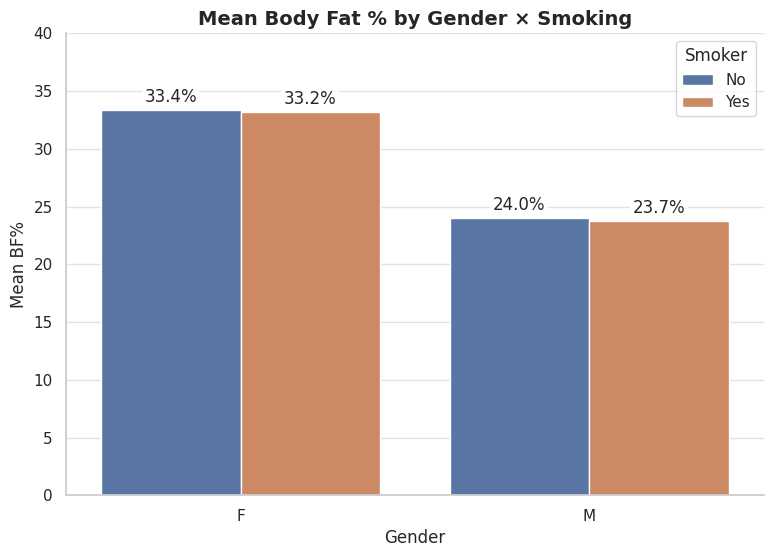

In [27]:
combined = (df.groupby(['Gender', 'Smoker'])
              .agg(mean_BMI=('BMI', 'mean'), mean_BF=('BF%', 'mean'), count=('BMI', 'count'))
              .round(2)
              .reset_index())
display(combined)

print("Höchster mittlerer BF%:", combined.loc[combined['mean_BF'].idxmax(), ['Gender', 'Smoker']].tolist())
print("Niedrigster mittlerer BMI:", combined.loc[combined['mean_BMI'].idxmin(), ['Gender', 'Smoker']].tolist())

plt.figure(figsize=(9, 6))
ax = sns.barplot(data=combined, x='Gender', y='mean_BF', hue='Smoker', errorbar=None)
add_bar_labels(ax, '%.1f%%')
ax.set_ylim(0, 40)
plt.title('Mean Body Fat % by Gender × Smoking')
plt.xlabel('Gender')
plt.ylabel('Mean BF%')
plt.show()

**Interpretation:** Den höchsten mittleren Körperfettanteil haben **nichtrauchende Frauen** (33,4 %), den niedrigsten mittleren BMI **rauchende Frauen** (22,8). Innerhalb jedes Geschlechts unterscheiden sich Raucher und Nichtraucher kaum (BF% höchstens 0,3 Punkte, BMI rund 0,1 Punkte). Der große Unterschied besteht zwischen den Geschlechtern (Frauen rund 33 %, Männer rund 24 % BF%), und der steckt in der Formel (−10,8 für Männer). Das Rauchen spielt für den Körperfettanteil in diesem Datensatz keine erkennbare Rolle.

### Question 6 — Sedentary people and body fat health

**Vorgehen:** Ich filtere auf Personen mit dem Aktivitätslevel `Sedentary`, wende `healthy_bf()` mit `.apply(axis=1)` zeilenweise an und berechne den Anteil mit gesundem Körperfett je Geschlecht. Ein Chi-Quadrat-Test prüft den Unterschied.

,Gender,healthy_count,total,healthy_share,healthy_percent
0,F,2495,8171,0.305348,30.5
1,M,3084,8785,0.351053,35.1


Chi-Quadrat-Test Geschlecht vs. gesund: p = 2.74e-10
Datengrundlage des Diagramms (Anzahl):


Gender,F,M
healthy_label,,
Healthy BF%,2495,3084
Unhealthy BF%,5676,5701


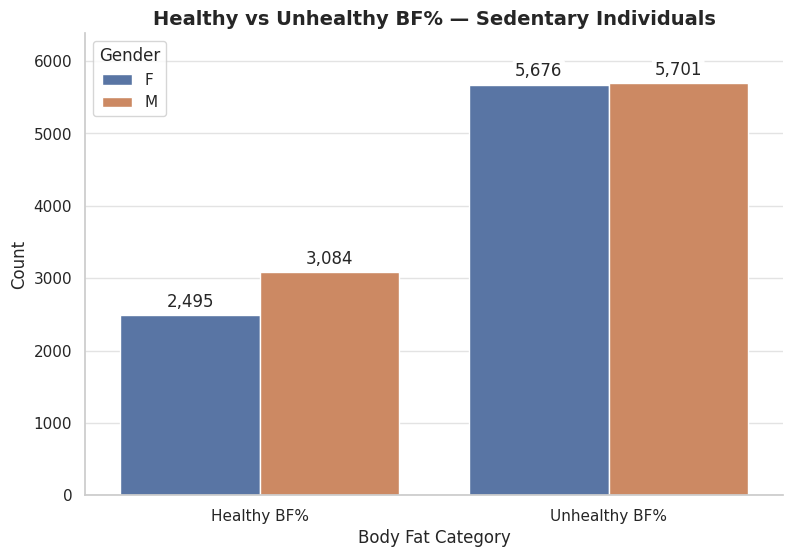

In [28]:
df_sed = df[df['Activity_Level'] == 'Sedentary'].copy()
df_sed['healthy_bf_flag'] = df_sed.apply(healthy_bf, axis=1)
df_sed['healthy_label'] = df_sed['healthy_bf_flag'].map({True: 'Healthy BF%', False: 'Unhealthy BF%'})

sed_stats = (df_sed.groupby('Gender')['healthy_bf_flag']
                   .agg(healthy_count='sum', total='count', healthy_share='mean')
                   .reset_index())
sed_stats['healthy_percent'] = (sed_stats['healthy_share'] * 100).round(1)
display(sed_stats)

chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(df_sed['Gender'], df_sed['healthy_bf_flag']))
print(f"Chi-Quadrat-Test Geschlecht vs. gesund: p = {p:.2e}")

print("Datengrundlage des Diagramms (Anzahl):")
display(pd.crosstab(df_sed['healthy_label'], df_sed['Gender']))

plt.figure(figsize=(9, 6))
ax = sns.countplot(data=df_sed, x='healthy_label', hue='Gender', order=['Healthy BF%', 'Unhealthy BF%'])
add_bar_labels(ax, '{:,.0f}')
ax.margins(y=0.12)
plt.title('Healthy vs Unhealthy BF% — Sedentary Individuals')
plt.xlabel('Body Fat Category')
plt.ylabel('Count')
plt.show()

**Interpretation:** Sitzende **Männer** erreichen mit 35,1 % (3.084 von 8.785) häufiger einen gesunden Körperfettanteil als sitzende Frauen mit 30,5 % (2.495 von 8.171). Der Unterschied ist statistisch deutlich (p < 0,001). Der Countplot zeigt es ebenfalls: Der Balken „Healthy" ist bei Männern höher. Im gesamten Datensatz ist das Muster gleich (Männer 42,4 %, Frauen 35,2 %). Warum das so ist, zeigen die Daten nicht; die Grenzwerte in `healthy_bf_ranges` und die Formel (Männer −10,8) wirken zusammen.

### Question 7 — Health metrics across age groups

**Vorgehen:** Mit Boolean Indexing bilde ich die fünf Altersgruppen aus `healthy_bf_ranges` und berechne je Gruppe mittleren BMI, mittleren BF% und den Anteil mit gesundem BF%. Die Ergebnisse stehen in einem Summary-DataFrame, dazu kommt ein Lineplot für BMI und BF%.

,Age_Group,Mean_BMI,Mean_BF%,Healthy_BF%,Count
0,18-29,22.65,21.48,81.5,9524
1,30-39,22.65,23.91,62.5,7859
2,40-49,22.94,26.78,43.3,7957
3,50-59,23.54,29.80,29.0,7930
4,60+,24.64,34.66,6.4,16731


Datengrundlage des Diagramms:


,Age_Group,Metric,Value
0,18-29,Mean_BMI,22.65
1,30-39,Mean_BMI,22.65
2,40-49,Mean_BMI,22.94
3,50-59,Mean_BMI,23.54
4,60+,Mean_BMI,24.64
5,18-29,Mean_BF%,21.48
6,30-39,Mean_BF%,23.91
7,40-49,Mean_BF%,26.78
8,50-59,Mean_BF%,29.80
9,60+,Mean_BF%,34.66


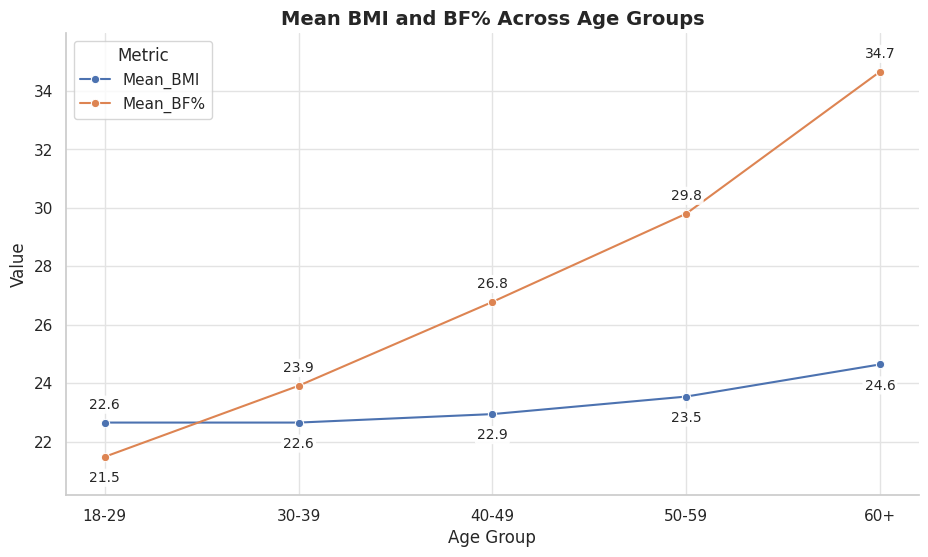

In [29]:
age_groups = {
    '18-29': (df['Age'] >= 18) & (df['Age'] <= 29),
    '30-39': (df['Age'] >= 30) & (df['Age'] <= 39),
    '40-49': (df['Age'] >= 40) & (df['Age'] <= 49),
    '50-59': (df['Age'] >= 50) & (df['Age'] <= 59),
    '60+':   (df['Age'] >= 60),
}

rows = []
for name, mask in age_groups.items():
    g = df[mask]
    rows.append({'Age_Group': name,
                 'Mean_BMI': round(g['BMI'].mean(), 2),
                 'Mean_BF%': round(g['BF%'].mean(), 2),
                 'Healthy_BF%': round(g['bf_healthy'].mean() * 100, 1),
                 'Count': len(g)})
summary_df = pd.DataFrame(rows)
display(summary_df)

plot_df = summary_df.melt(id_vars='Age_Group', value_vars=['Mean_BMI', 'Mean_BF%'],
                          var_name='Metric', value_name='Value')
print("Datengrundlage des Diagramms:")
display(plot_df)
plt.figure(figsize=(11, 6))
ax = sns.lineplot(data=plot_df, x='Age_Group', y='Value', hue='Metric', marker='o')
wide = summary_df.set_index('Age_Group')[['Mean_BMI', 'Mean_BF%']]
for i, (grp, row) in enumerate(wide.iterrows()):
    upper = row.idxmax()
    for metric, val in row.items():
        ax.annotate(f'{val:.1f}', (i, val), textcoords='offset points',
                    xytext=(0, 10 if metric == upper else -18), ha='center', fontsize=10,
                    bbox=dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.9))
ax.margins(y=0.1)
plt.title('Mean BMI and BF% Across Age Groups')
plt.xlabel('Age Group')
plt.ylabel('Value')
plt.show()

**Interpretation:** Der mittlere Körperfettanteil steigt deutlich von 21,5 % (18–29) auf 34,7 % (60+), der mittlere BMI nur von 22,7 auf 24,6. Der Anteil mit gesundem Körperfett fällt von 81,5 % über 62,5 %, 43,3 % und 29,0 % auf nur 6,4 % bei den über 60-Jährigen. Das ist bemerkenswert, weil die Grenzwerte mit dem Alter großzügiger werden; der Körperfettanteil steigt schneller. Der Grund liegt in der Formel: Pro Lebensjahr kommen 0,23 Prozentpunkte BF% dazu, auch bei gleichem BMI. Die Gruppe 60+ ist mit 16.731 Personen die größte. Einschränkung: Es ist ein Querschnittsvergleich verschiedener Personen, kein Verlauf einzelner Menschen.

## Part 2 — Your Own Questions

### Own Question 1 — Cross-categorical (Constraint 1)

**Frage:** Bleibt der Unterschied im Körperfettanteil zwischen den Aktivitätsleveln bestehen, wenn man gleichzeitig Altersgruppe und Geschlecht berücksichtigt?

**Warum diese Frage:** In Frage 2 hatten sehr aktive Personen den niedrigsten Körperfettanteil. Das sieht wie ein Beleg dafür aus, dass Bewegung Körperfett senkt. Da `BF%` aber aus BMI, Alter und Geschlecht berechnet wird und die Aktivitätsgruppen unterschiedlich alt sind, will ich prüfen, ob der Effekt nach Kontrolle von Alter und Geschlecht bestehen bleibt.

Vollständige Tabelle (Activity Level × Age Group × Gender):


,Age_Group,Activity_Level,Gender,mean_BMI,mean_BF,healthy_pct,count
0,18-29,Lightly Active,F,22.14,26.58,72.83,1351
1,18-29,Lightly Active,M,23.27,17.14,87.01,1501
2,18-29,Moderately Active,F,21.97,26.36,74.54,1520
3,18-29,Moderately Active,M,23.19,17.05,88.67,1748
4,18-29,Sedentary,F,21.93,26.32,75.87,924
5,18-29,Sedentary,M,23.21,17.05,87.46,1037
6,18-29,Very Active,F,22.06,26.45,73.31,697
7,18-29,Very Active,M,23.13,16.94,90.35,746
8,30-39,Lightly Active,F,22.08,29.02,51.01,1331
9,30-39,Lightly Active,M,23.18,19.56,71.52,1654


Mittlerer BF% je Altersgruppe und Aktivitätslevel (beide Geschlechter zusammen):


Activity_Level,Lightly Active,Moderately Active,Sedentary,Very Active
Age_Group,,,,
18-29,21.61,21.38,21.42,21.54
30-39,23.78,24.03,24.01,23.68
40-49,26.81,26.77,26.64,27.17
50-59,29.70,29.69,29.89,30.05
60+,34.64,34.60,34.68,34.78


Datengrundlage des Diagramms (mittlerer BF% je Geschlecht, Altersgruppe und Aktivitätslevel):


Activity_Level    Lightly Active  Moderately Active  Sedentary  Very Active
Gender Age_Group                                                           
F      18-29               26.58              26.36      26.32        26.45
       30-39               29.02              29.08      28.81        28.68
       40-49               31.70              31.63      31.48        31.86
       50-59               34.55              34.69      34.62        34.96
       60+                 39.38              39.29      39.52        39.64
M      18-29               17.14              17.05      17.05        16.94
       30-39               19.56              19.57      19.56        19.73
       40-49               22.25              22.31      22.20        22.31
       50-59               25.33              25.26      25.25        25.28
       60+                 30.28              30.25      30.21        30.59

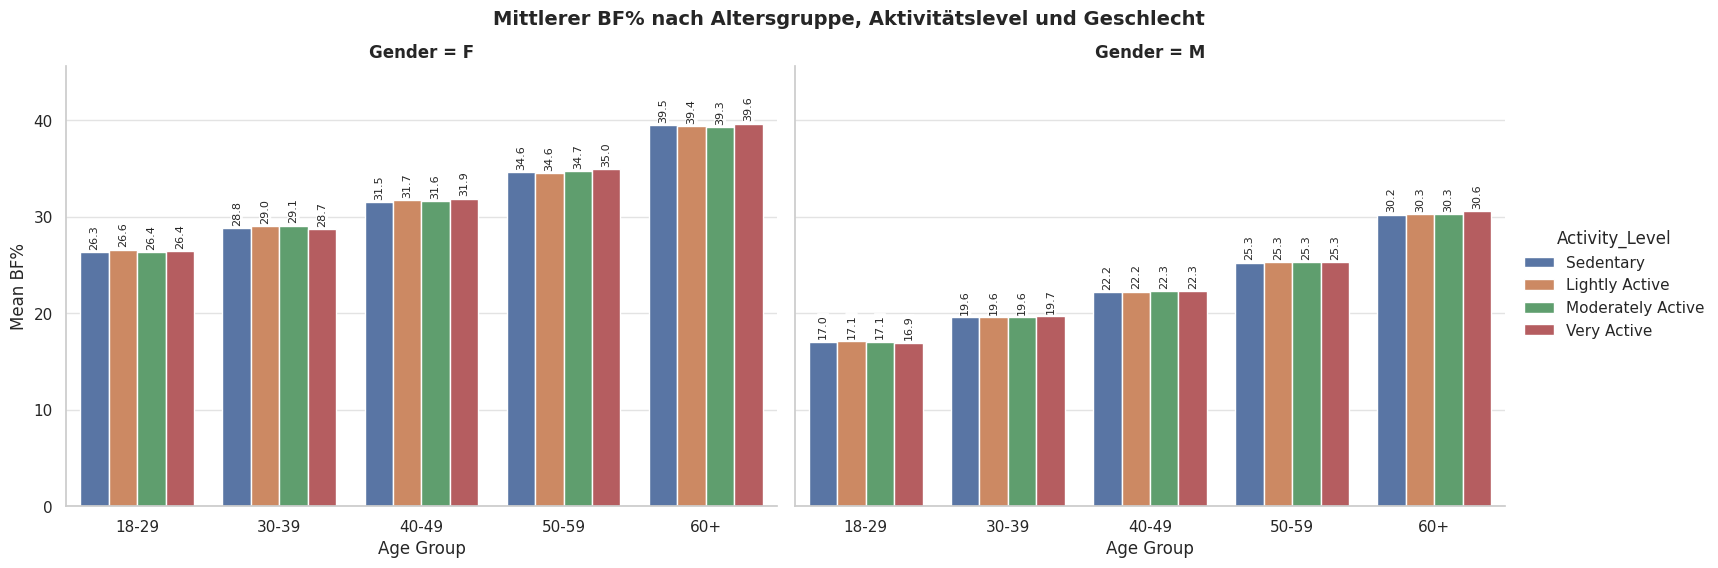

Mittleres Alter je Aktivitätslevel:


,Age
Activity_Level,
Lightly Active,49.6
Moderately Active,44.8
Sedentary,53.1
Very Active,41.7


Altersverteilung je Aktivitätslevel (%):


Age_Group,18-29,30-39,40-49,50-59,60+
Activity_Level,,,,,
Lightly Active,16.2,17.0,17.4,15.8,33.6
Moderately Active,28.1,16.6,16.9,12.5,26.0
Sedentary,11.6,14.1,13.8,19.4,41.1
Very Active,37.7,14.4,15.3,10.9,21.7


In [30]:
df['Age_Group'] = pd.cut(df['Age'], bins=[17, 29, 39, 49, 59, 120],
                         labels=['18-29', '30-39', '40-49', '50-59', '60+'])   # 17, damit 18-Jährige dabei sind

cross = (df.groupby(['Age_Group', 'Activity_Level', 'Gender'], observed=True)
           .agg(mean_BMI=('BMI', 'mean'), mean_BF=('BF%', 'mean'),
                healthy_pct=('bf_healthy', lambda s: s.mean() * 100), count=('BMI', 'count'))
           .round(2)
           .reset_index())
print("Vollständige Tabelle (Activity Level × Age Group × Gender):")
display(cross.sort_values(['Age_Group', 'Activity_Level', 'Gender']))

print("Mittlerer BF% je Altersgruppe und Aktivitätslevel (beide Geschlechter zusammen):")
display(df.pivot_table(index='Age_Group', columns='Activity_Level', values='BF%', aggfunc='mean', observed=True).round(2))

print("Datengrundlage des Diagramms (mittlerer BF% je Geschlecht, Altersgruppe und Aktivitätslevel):")
display(df.pivot_table(index=['Gender', 'Age_Group'], columns='Activity_Level', values='BF%',
                       aggfunc='mean', observed=True).round(2))

g = sns.catplot(data=df, x='Age_Group', y='BF%', hue='Activity_Level', col='Gender',
                kind='bar', errorbar=None, height=5.5, aspect=1.4,
                hue_order=['Sedentary', 'Lightly Active', 'Moderately Active', 'Very Active'])
for ax in g.axes.flat:
    for c in ax.containers:
        ax.bar_label(c, fmt='%.1f', fontsize=8, rotation=90, padding=2,
                     bbox=dict(boxstyle='round,pad=0.1', facecolor='white', edgecolor='none', alpha=0.9))
    ax.margins(y=0.15)
g.set_axis_labels('Age Group', 'Mean BF%')
g.fig.suptitle('Mittlerer BF% nach Altersgruppe, Aktivitätslevel und Geschlecht', y=1.03, fontsize=14, fontweight='bold')
plt.show()

# Warum sieht der Aktivitätseffekt in Frage 2 trotzdem aus wie ein Effekt?
print("Mittleres Alter je Aktivitätslevel:")
display(df.groupby('Activity_Level')['Age'].mean().round(1))
print("Altersverteilung je Aktivitätslevel (%):")
display((pd.crosstab(df['Activity_Level'], df['Age_Group'], normalize='index') * 100).round(1))

**Interpretation:** Innerhalb jeder Altersgruppe liegen die vier Aktivitätslevel praktisch gleich (z. B. 18–29: 21,4–21,6 %; 60+: 34,6–34,8 %), bei beiden Geschlechtern. Die Linien liegen übereinander. Der Unterschied aus Frage 2 verschwindet also, sobald das Alter konstant ist. Er entsteht, weil die Aktivitätsgruppen unterschiedlich alt sind: 38 % der sehr Aktiven sind 18–29 Jahre alt, aber nur 12 % der Sitzenden; 41 % der Sitzenden sind über 60 (sehr Aktive: 22 %). Das ist ein Confounding-Effekt (Störvariable Alter), kein Aktivitätseffekt. Das heißt nicht, dass Bewegung nutzlos ist, sondern dass dieser Datensatz es nicht belegen kann, weil `BF%` berechnet und nicht gemessen ist.

### Own Question 2 — Text-based (Constraint 2)

**Frage:** How do mean BMI, mean body fat percentage and the proportion of healthy BF% differ across categories derived from the `message` column? Do individuals receiving different messages show distinct health profiles?

**Vorgehen:** Ich prüfe zuerst, welche Nachrichten es wirklich gibt. Es sind nur vier Texte. Die ursprünglich angenommenen Kategorien („Reduce BF%", „Increase Activity", „Risk Warning", „General Advice") kommen in den Daten nicht vor; das Stichwort „risk" steckt zum Beispiel in „brisk". Deshalb leite ich die Kategorien aus den echten Texten ab (ganze Phrasen statt Einzelwörter) und berechne pro Nachrichtentyp mittleren BMI, mittleren BF% und den Anteil gesunder Werte. Zusätzlich prüfe ich, wie viele Personen mit der Nachricht „healthy range" einen ungesunden Körperfettanteil haben.

Verschiedene Nachrichten: 4

Nachricht vs. BMI-Kategorie (Zeilen = Nachrichtentyp):


bmi_category,Normal weight,Obese,Overweight,Underweight
message_type,,,,
Healthy-range,37022,0,0,0
Obese,0,169,0,0
Overweight,0,0,12352,0
Underweight,0,0,0,458


Datengrundlage der Diagramme:


,message_type,mean_BMI,mean_BF,healthy_pct,count
0,Underweight,17.92,21.49,97.16,458
1,Healthy-range,22.57,27.18,50.45,37022
2,Overweight,26.40,32.31,2.99,12352
3,Obese,30.84,38.22,0.00,169



Personen mit 'Great work'-Nachricht, aber ungesundem BF%: 18,343 (49.5 %)


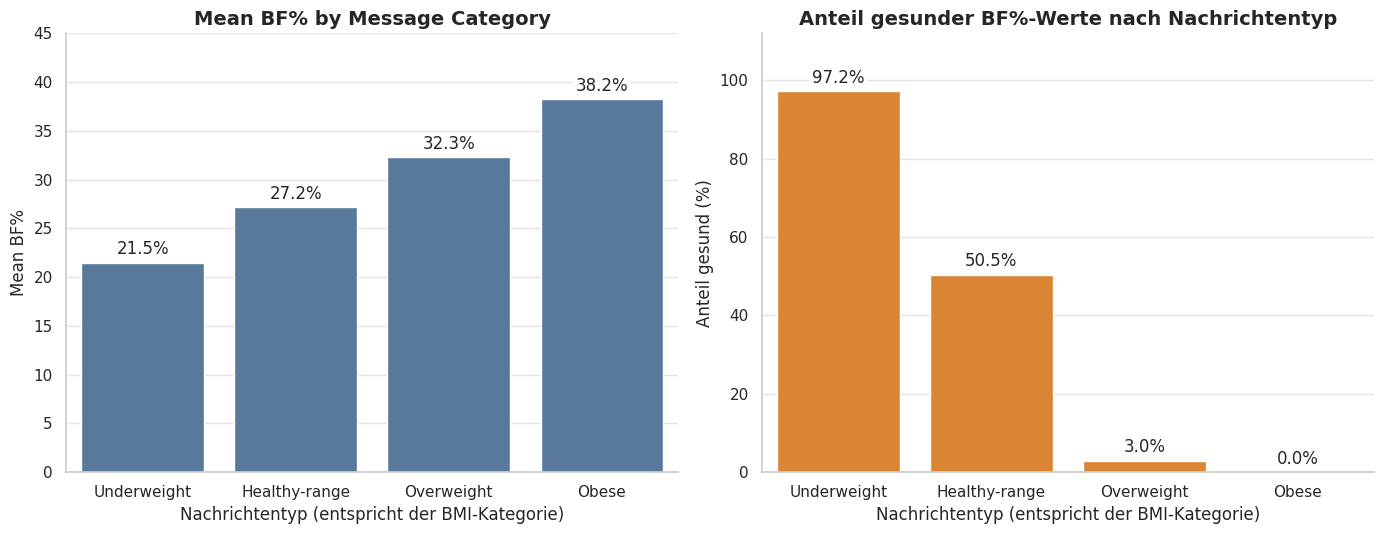

In [31]:
print("Verschiedene Nachrichten:", df['message'].nunique())

def message_type(msg):
    m = msg.lower()
    if 'healthy range' in m:      return 'Healthy-range'
    if 'overweight range' in m:   return 'Overweight'
    if 'underweight' in m:        return 'Underweight'
    if 'obese range' in m:        return 'Obese'
    return 'Other'

df['message_type'] = df['message'].apply(message_type)
type_order = ['Underweight', 'Healthy-range', 'Overweight', 'Obese']

print("\nNachricht vs. BMI-Kategorie (Zeilen = Nachrichtentyp):")
display(pd.crosstab(df['message_type'], df['bmi_category']))

msg_stats = (df.groupby('message_type')
               .agg(mean_BMI=('BMI', 'mean'), mean_BF=('BF%', 'mean'),
                    healthy_pct=('bf_healthy', lambda s: s.mean() * 100), count=('BMI', 'count'))
               .round(2)
               .loc[type_order]
               .reset_index())
print("Datengrundlage der Diagramme:")
display(msg_stats)

hidden = df[(df['message_type'] == 'Healthy-range') & (~df['bf_healthy'])]
print(f"\nPersonen mit 'Great work'-Nachricht, aber ungesundem BF%: {len(hidden):,} "
      f"({len(hidden) / (df['message_type'] == 'Healthy-range').sum() * 100:.1f} %)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.barplot(data=msg_stats, x='message_type', y='mean_BF', color='#4C78A8', ax=axes[0])
add_bar_labels(axes[0], '%.1f%%')
axes[0].set_ylim(0, 45)
axes[0].set_title('Mean BF% by Message Category')
axes[0].set_ylabel('Mean BF%')

sns.barplot(data=msg_stats, x='message_type', y='healthy_pct', color='#F58518', ax=axes[1])
add_bar_labels(axes[1], '%.1f%%')
axes[1].set_ylim(0, 112)
axes[1].set_title('Anteil gesunder BF%-Werte nach Nachrichtentyp')
axes[1].set_ylabel('Anteil gesund (%)')

for ax in axes:
    ax.set_xlabel('Nachrichtentyp (entspricht der BMI-Kategorie)')
plt.tight_layout()
plt.show()

**Interpretation:** Die Spalte `message` enthält nur vier verschiedene Texte, jeder gehört genau zu einer BMI-Kategorie. Sie liefert keine zusätzliche Information über den BMI hinaus. Die Gesundheitsprofile unterscheiden sich klar, aber nur, weil die Nachrichten den BMI-Gruppen entsprechen: Der mittlere Körperfettanteil steigt von 21,5 % (Underweight) über 27,2 % (Healthy-range) und 32,3 % (Overweight) auf 38,2 % (Obese). Der Anteil gesunder Werte fällt von 97,2 % über 50,5 % und 3,0 % auf 0 %.

Die Nachrichten passen damit nur teilweise zum Körperfett: Rund jede zweite Person (49,5 %, etwa 18.300 Personen), die „Great work – your BMI is in the healthy range" liest, hat einen ungesunden Körperfettanteil. Eine rein BMI-basierte Rückmeldung erkennt also verdecktes Risiko bei normalem BMI nicht. Eine Empfehlung wäre, `BF%` zusätzlich in die Nachricht einzubeziehen.

### Own Question 3 — Justified (Constraint 3)

**Frage:** Welche einzelne Variable sagt am besten voraus, ob jemand einen gesunden Körperfettanteil hat?

**Warum diese Frage wichtig ist:** Wer Gesundheitsempfehlungen oder Screenings gestalten will, muss wissen, welche Merkmale den Körperfett-Status am stärksten bestimmen. Zugleich hilft die Frage zu erkennen, welche Merkmale in diesem Datensatz *keinen* Einfluss haben (zum Beispiel Rauchen).

**Vorgehen:** Schritt 1 zeigt die Zusammenhänge visuell (BMI, Aktivitätslevel, Geschlecht und Alter gegen BF%). Schritt 2 quantifiziert die Vorhersagekraft jeder Variable einzeln mit der AUC eines einfachen logistischen Modells (0,5 = kein Vorhersagewert, 1,0 = perfekt) und ergänzt die Anteile gesunder Werte je Altersgruppe.

#### Schritt 1 — Visualisierung der Einflussgrößen

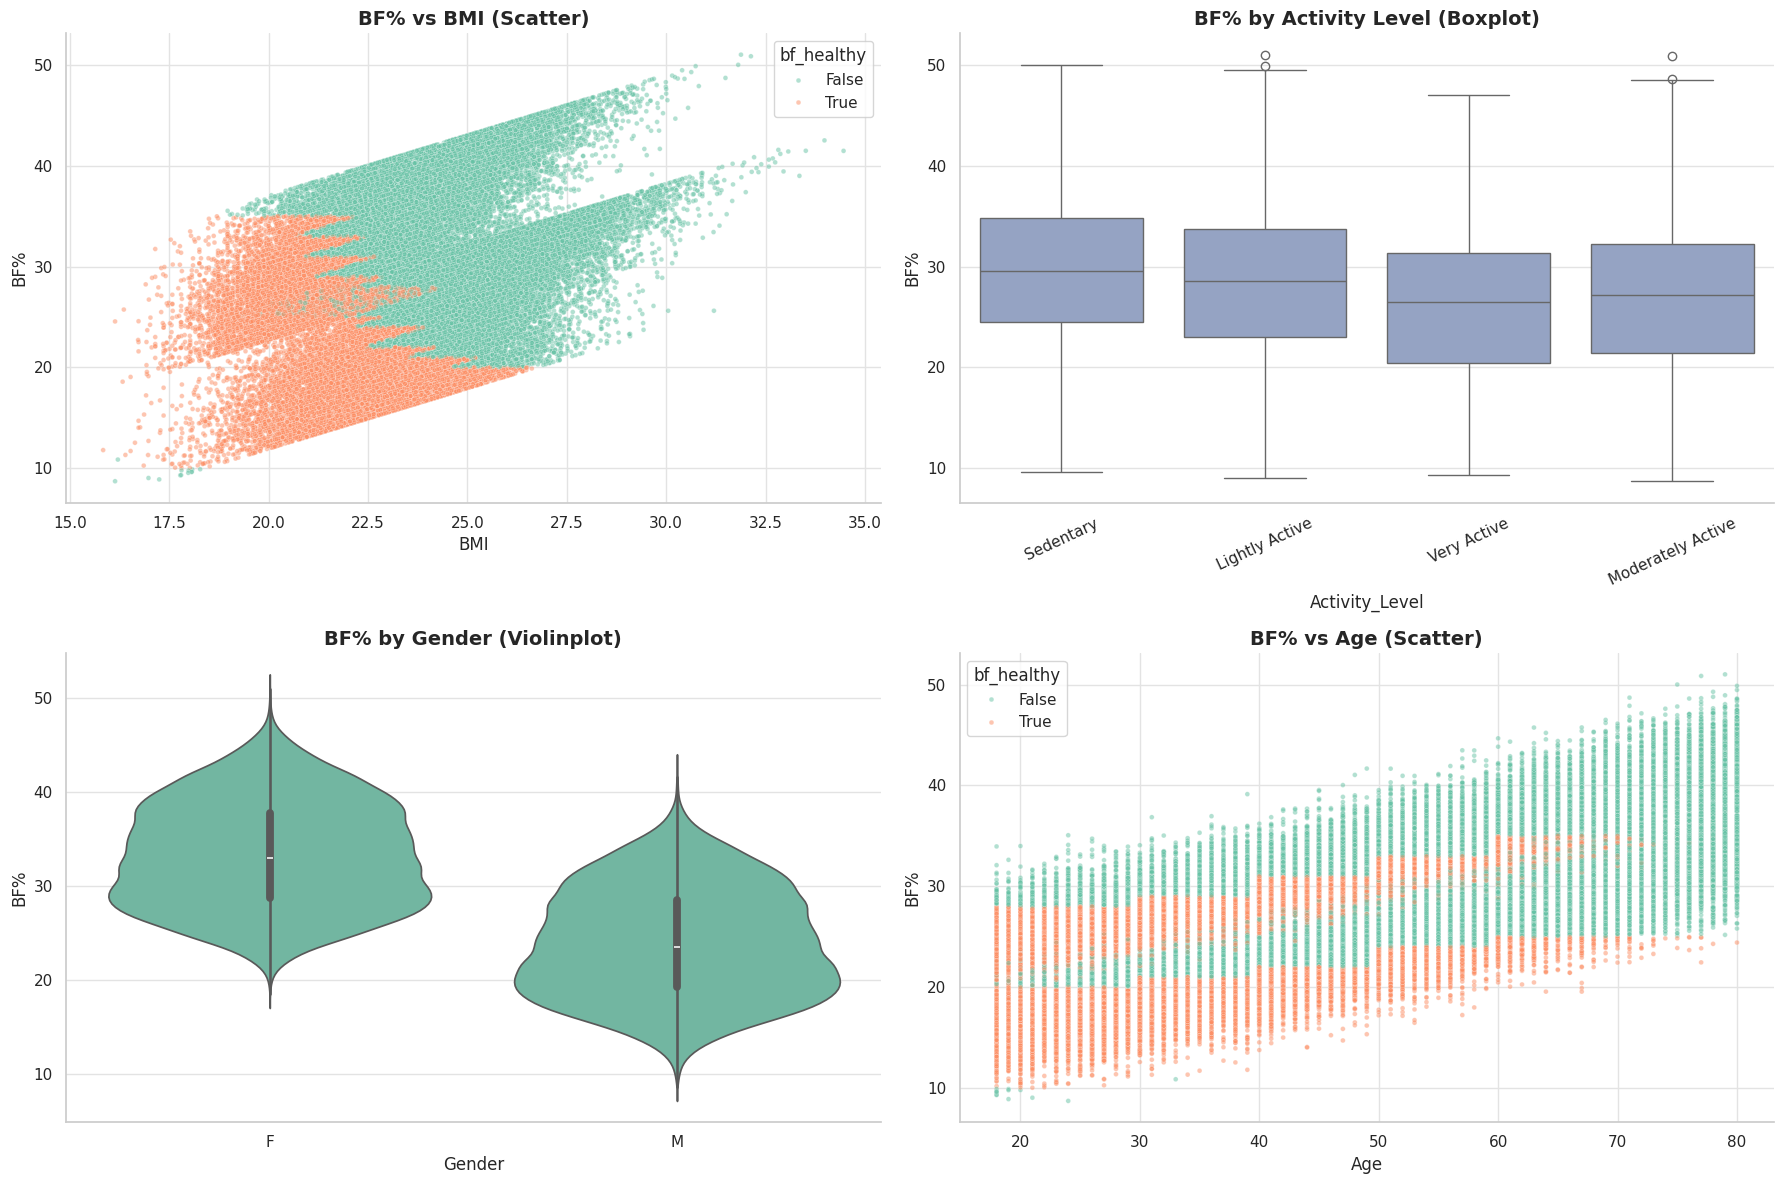

Datengrundlage (Median und Mittelwert BF%):


median   mean
nach Aktivität  Lightly Active      28.54  28.54
                Moderately Active   27.16  27.20
                Sedentary           29.57  29.60
                Very Active         26.43  26.51
nach Geschlecht F                   33.06  33.35
                M                   23.58  23.96

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1 — BMI vs BF%
sns.scatterplot(data=df, x='BMI', y='BF%', hue='bf_healthy', palette='Set2', s=12, alpha=0.5, ax=axes[0, 0])
axes[0, 0].set_title('BF% vs BMI (Scatter)')

# 2 — BF% nach Aktivitätslevel
sns.boxplot(data=df, x='Activity_Level', y='BF%', color='#8DA0CB', ax=axes[0, 1])
axes[0, 1].set_title('BF% by Activity Level (Boxplot)')
axes[0, 1].tick_params(axis='x', rotation=25)

# 3 — BF% nach Geschlecht
sns.violinplot(data=df, x='Gender', y='BF%', color='#66C2A5', ax=axes[1, 0])
axes[1, 0].set_title('BF% by Gender (Violinplot)')

# 4 — BF% vs Alter
sns.scatterplot(data=df, x='Age', y='BF%', hue='bf_healthy', palette='Set2', s=12, alpha=0.5, ax=axes[1, 1])
axes[1, 1].set_title('BF% vs Age (Scatter)')

plt.tight_layout()
plt.show()

print("Datengrundlage (Median und Mittelwert BF%):")
display(pd.concat({'nach Aktivität': df.groupby('Activity_Level')['BF%'].agg(['median', 'mean']),
                   'nach Geschlecht': df.groupby('Gender')['BF%'].agg(['median', 'mean'])}).round(2))

**Zu den Diagrammen:** Der Scatterplot BMI vs. BF% zeigt zwei parallele Bänder (Männer und Frauen) mit klar steigendem BF% bei steigendem BMI. Der Boxplot zeigt bei höherer Aktivität etwas niedrigere Werte (Mittelwert 26,5 % bei Very Active, 29,6 % bei Sedentary), die Verteilungen überlappen aber stark; dieser Unterschied entsteht über das Alter (siehe Own Question 1). Der Violinplot einen deutlichen Unterschied zwischen Frauen (rund 33 %) und Männern (rund 24 %), und der Scatterplot gegen das Alter einen steigenden Trend. Diese Muster entstehen größtenteils durch die Formel, mit der `BF%` berechnet wurde.

#### Schritt 2 — Vorhersagekraft quantifizieren

,Variable,AUC
0,BMI,0.889
1,Age,0.858
2,Activity_Level,0.566
3,Gender,0.538
4,Smoker,0.503


,Age_Group,healthy_pct
0,18-29,81.5
1,30-39,62.5
2,40-49,43.3
3,50-59,29.0
4,60+,6.4


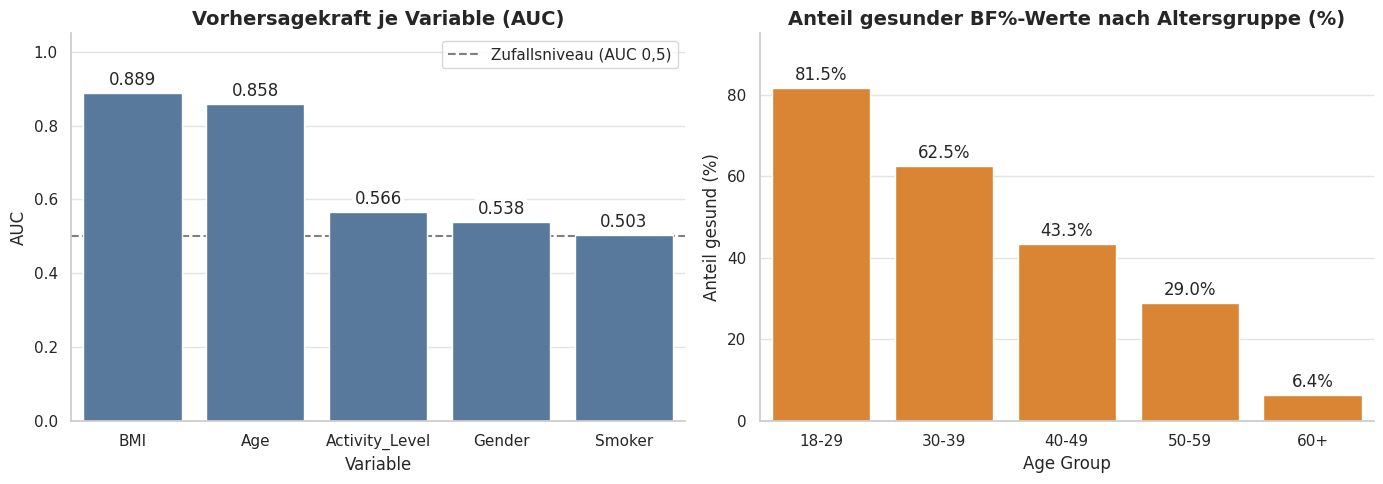

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

y = df['bf_healthy'].astype(int)

def single_auc(cols):
    X = pd.get_dummies(df[cols], drop_first=True).astype(float)
    X = (X - X.mean()) / X.std()
    model = LogisticRegression(max_iter=1000).fit(X, y)
    return roc_auc_score(y, model.predict_proba(X)[:, 1])

auc_table = pd.DataFrame({
    'Variable': ['BMI', 'Age', 'Activity_Level', 'Gender', 'Smoker'],
    'AUC': [single_auc(['BMI']), single_auc(['Age']), single_auc(['Activity_Level']),
            single_auc(['Gender']), single_auc(['Smoker'])]
}).sort_values('AUC', ascending=False).round(3)
display(auc_table)

healthy_by_age = (df.groupby('Age_Group', observed=True)['bf_healthy'].mean().mul(100).round(1)
                    .reset_index(name='healthy_pct'))
display(healthy_by_age)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=auc_table, x='Variable', y='AUC', color='#4C78A8', ax=axes[0])
add_bar_labels(axes[0], '%.3f')
axes[0].set_ylim(0, 1.05)
axes[0].axhline(0.5, color='grey', linestyle='--', zorder=0, label='Zufallsniveau (AUC 0,5)')
axes[0].legend(loc='upper right')
axes[0].set_title('Vorhersagekraft je Variable (AUC)')
sns.barplot(data=healthy_by_age, x='Age_Group', y='healthy_pct', color='#F58518', ax=axes[1])
add_bar_labels(axes[1], '%.1f%%')
axes[1].set_ylim(0, 95)
axes[1].set_title('Anteil gesunder BF%-Werte nach Altersgruppe (%)')
axes[1].set_xlabel('Age Group')
axes[1].set_ylabel('Anteil gesund (%)')
plt.tight_layout()
plt.show()

**Interpretation:** Als einzelne Variable sagt der **BMI** den gesunden Körperfettanteil am besten voraus (AUC 0,89), knapp gefolgt vom **Alter** (0,86). Aktivität (0,57), Geschlecht (0,54) und Rauchen (0,50) sind schwach; Rauchen liegt auf Zufallsniveau. Beim Anteil gesunder Werte ist der Abstand zwischen den Altersgruppen mit 75 Prozentpunkten (81,5 % bis 6,4 %) bei weitem am größten. Der Aktivitätswert von 0,57 kommt nur über das Alter zustande (siehe Own Question 1).

**Wichtige Einordnung:** Dieses Ergebnis ist zirkulär. `BF%` wird aus BMI, Alter und Geschlecht berechnet, und `bf_healthy` aus `BF%`. Deshalb sagen BMI und Alter es fast perfekt voraus (zusammen mit dem Geschlecht AUC 0,99), und Aktivität und Rauchen verbessern die Vorhersage nicht. Das Ergebnis zeigt, wie der Datensatz entstanden ist, nicht, was Körperfett in der Realität bestimmt. Für echte Aussagen bräuchte man gemessene Körperfettwerte.

## Part 3 — Summary

**Drei wichtigste Erkenntnisse:**

1. **Das Alter bestimmt die Werte.** Der Körperfettanteil steigt von 21,5 % (18–29) auf 34,7 % (60+), der Anteil gesunder Werte fällt von 82 % auf 6 %.
2. **Aktivität und Rauchen zeigen keinen eigenen Effekt.** Die Unterschiede entstehen durch unterschiedliche Alters- und Geschlechtsverteilungen der Gruppen: Sehr Aktive sind jünger, Raucher häufiger männlich. Innerhalb von Altersgruppen und Geschlechtern verschwinden die Unterschiede.
3. **`BF%` ist in diesem Datensatz berechnet, nicht gemessen.** Deshalb sind BMI und Alter fast perfekte Prädiktoren. Die Spalte `message` enthält nur die BMI-Kategorie in Textform und erkennt verdecktes Risiko bei Normalgewicht nicht (jede zweite Person mit „Great work" hat einen ungesunden Körperfettanteil).

**Was mich überrascht hat:** Der scheinbar deutliche Einfluss der Aktivität auf den Körperfettanteil verschwindet, sobald man das Alter berücksichtigt. Ebenso überraschte mich, dass Raucher auf den ersten Blick „gesünder" aussehen, obwohl nur die Geschlechtsverteilung dahintersteckt. Auch die Datenqualität war nicht so sauber, wie die erste Inspektion vermuten ließ (eine ungültige Aktivitätskategorie, 96 Duplikate).

**Was ich als Nächstes untersuchen würde:** Gemessene Körperfettwerte statt der Formel verwenden und prüfen, ob die Deurenberg-Formel bei älteren Menschen und Sportlern zuverlässig ist. Außerdem Alter, Geschlecht und Aktivität gleichzeitig in einem Regressionsmodell kontrollieren und die Duplikate gezielt untersuchen.